# 01 — EDA e limpeza

**Projeto:** Segmentação de clientes com RFM e clusterização
**Dataset:** Online Retail II (UCI), transações de uma loja online do Reino Unido (dez/2009 a dez/2011)

**Objetivos deste notebook**
1. Carregar as duas abas da planilha e juntar em uma única tabela
2. Diagnosticar problemas de qualidade dos dados
3. Limpar e deixar apenas compras válidas de clientes identificados
4. Explorar o comportamento de compra (receita no tempo, países, clientes)
5. Salvar a base limpa para a etapa de RFM

## 1. Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

RAW = Path("../data/raw/online_retail_II.xlsx")
INTERIM = Path("../data/interim/online_retail_II.csv")
PROCESSED = Path("../data/processed/transactions_clean.csv")
FIGURES = Path("../reports/figures")

## 2. Carga dos dados

A planilha original tem **duas abas** (2009-2010 e 2010-2011). Na primeira execução a leitura do Excel é lenta, então salvo um CSV em `data/interim/` e uso ele nas próximas.

In [2]:
if INTERIM.exists():
    df = pd.read_csv(
        INTERIM,
        parse_dates=["InvoiceDate"],
        dtype={"Invoice": str, "StockCode": str},
    )
else:
    sheets = pd.read_excel(RAW, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
    print("Abas encontradas:", {nome: len(aba) for nome, aba in sheets.items()})
    df = pd.concat(sheets.values(), ignore_index=True)
    INTERIM.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(INTERIM, index=False)

df = df.rename(columns={"Customer ID": "CustomerID"})
df.shape

Abas encontradas: {'Year 2009-2010': 525461, 'Year 2010-2011': 541910}


(1067371, 8)

In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 3. Visão geral e qualidade dos dados

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 90.1+ MB


In [5]:
missing = df.isna().mean().sort_values(ascending=False).to_frame("pct_nulos")
missing

,pct_nulos
CustomerID,0.23
Description,0.00
StockCode,0.00
Invoice,0.00
Quantity,0.00
InvoiceDate,0.00
Price,0.00
Country,0.00


Clientes sem `CustomerID` não podem entrar em uma segmentação por cliente, então serão removidos. Agora os demais problemas que costumam aparecer nesse dataset:

In [6]:
df["IsCancel"] = df["Invoice"].str.startswith("C")

print(f"Linhas totais:                       {len(df):>10,}")
print(f"Cancelamentos (Invoice começa com C): {df['IsCancel'].sum():>9,} ({df['IsCancel'].mean():.1%})")
print(f"Quantity <= 0 fora dos cancelamentos: {((df['Quantity'] <= 0) & ~df['IsCancel']).sum():>9,}")
print(f"Price <= 0:                          {(df['Price'] <= 0).sum():>10,}")
print(f"Linhas duplicadas exatas:            {df.duplicated().sum():>10,}")

Linhas totais:                        1,067,371
Cancelamentos (Invoice começa com C):    19,494 (1.8%)
Quantity <= 0 fora dos cancelamentos:     3,457
Price <= 0:                               6,207
Linhas duplicadas exatas:                34,335


> **Atenção às duplicatas:** as duas abas se sobrepõem por alguns dias em dezembro de 2010, então parte das duplicatas vem dessa sobreposição. Removo as duplicatas exatas, sabendo que isso também pode eliminar algumas linhas legítimas repetidas dentro de uma mesma nota. Esse é um trade-off comum e vale registrar no README.

### Códigos de estoque que não são produtos

Alguns `StockCode` representam serviços e ajustes, como frete (`POST`), taxas e ajustes manuais. Eles inflam a receita sem representar compra de produto.

In [7]:
nao_produto = df["StockCode"].str.match(r"^[A-Za-z ]+$", na=False)
(
    df[nao_produto]
    .assign(Revenue=lambda d: d["Quantity"] * d["Price"])
    .groupby("StockCode")
    .agg(linhas=("Invoice", "size"), receita=("Revenue", "sum"))
    .sort_values("linhas", ascending=False)
    .head(15)
)

,linhas,receita
StockCode,,
POST,2122,"112,341.00"
DOT,1446,"322,647.47"
M,1421,"-82,796.32"
D,177,"-13,484.54"
S,104,"-6,065.80"
BANK CHARGES,102,"-35,562.63"
ADJUST,67,"6,835.24"
AMAZONFEE,43,"-260,763.58"
DCGSSGIRL,25,295.63


## 4. Limpeza

Regras aplicadas, nesta ordem:
1. Remover linhas duplicadas exatas
2. Remover linhas sem `CustomerID`
3. Remover cancelamentos (`Invoice` começando com `C`)
4. Manter apenas `Quantity > 0` e `Price > 0`
5. Remover códigos que não são produtos
6. Criar `Revenue = Quantity × Price`

In [8]:
n0 = len(df)

clean = df.drop_duplicates()
n1 = len(clean)

clean = clean.dropna(subset=["CustomerID"])
n2 = len(clean)

clean = clean[~clean["IsCancel"]]
n3 = len(clean)

clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
n4 = len(clean)

clean = clean[~clean["StockCode"].str.match(r"^[A-Za-z ]+$", na=False)].copy()
n5 = len(clean)

clean["CustomerID"] = clean["CustomerID"].astype(int)
clean["Revenue"] = clean["Quantity"] * clean["Price"]

funil = pd.DataFrame(
    {
        "etapa": [
            "Dados brutos",
            "Sem duplicatas",
            "Com CustomerID",
            "Sem cancelamentos",
            "Quantity e Price > 0",
            "Apenas produtos",
        ],
        "linhas": [n0, n1, n2, n3, n4, n5],
    }
)
funil["% do total"] = funil["linhas"] / n0 * 100
funil

,etapa,linhas,% do total
0,Dados brutos,1067371,100.00
1,Sem duplicatas,1033036,96.78
2,Com CustomerID,797885,74.75
3,Sem cancelamentos,779495,73.03
4,Quantity e Price > 0,779425,73.02
5,Apenas produtos,776840,72.78


## 5. Exploração

In [9]:
resumo = {
    "Período": f"{clean['InvoiceDate'].min():%d/%m/%Y} a {clean['InvoiceDate'].max():%d/%m/%Y}",
    "Clientes": f"{clean['CustomerID'].nunique():,}",
    "Notas fiscais": f"{clean['Invoice'].nunique():,}",
    "Produtos": f"{clean['StockCode'].nunique():,}",
    "Países": f"{clean['Country'].nunique():,}",
    "Receita total": f"{clean['Revenue'].sum():,.0f}",
}
pd.Series(resumo, name="Base limpa").to_frame()

,Base limpa
Período,01/12/2009 a 09/12/2011
Clientes,"5,853"
Notas fiscais,"36,613"
Produtos,"4,624"
Países,41
Receita total,"17,082,086"


### Receita ao longo do tempo

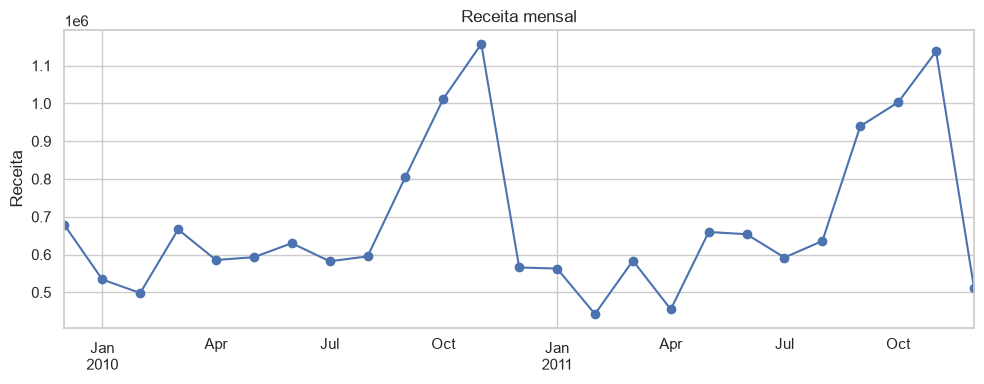

In [10]:
monthly = clean.set_index("InvoiceDate")["Revenue"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(marker="o", ax=ax)
ax.set_title("Receita mensal")
ax.set_xlabel("")
ax.set_ylabel("Receita")
plt.tight_layout()
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "01_receita_mensal.png", dpi=150)
plt.show()

Procure por **sazonalidade** (picos no fim do ano costumam aparecer em lojas de presentes) e por meses incompletos nas pontas da série.

### Receita por país

United Kingdom concentra 83.7% da receita


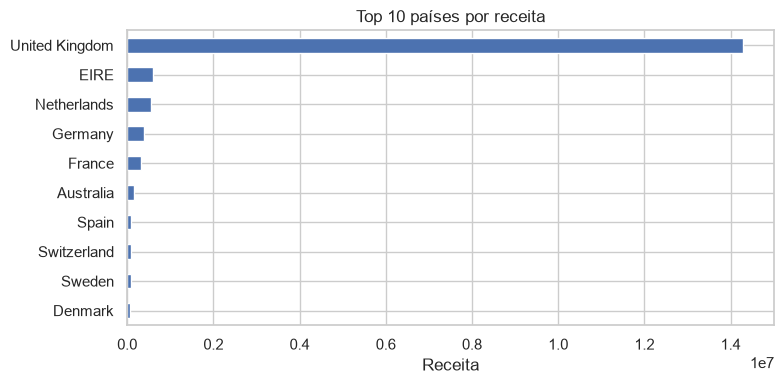

In [11]:
por_pais = clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
share_top = por_pais.iloc[0] / por_pais.sum()
print(f"{por_pais.index[0]} concentra {share_top:.1%} da receita")

fig, ax = plt.subplots(figsize=(8, 4))
por_pais.head(10).sort_values().plot.barh(ax=ax)
ax.set_title("Top 10 países por receita")
ax.set_xlabel("Receita")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Comportamento dos clientes

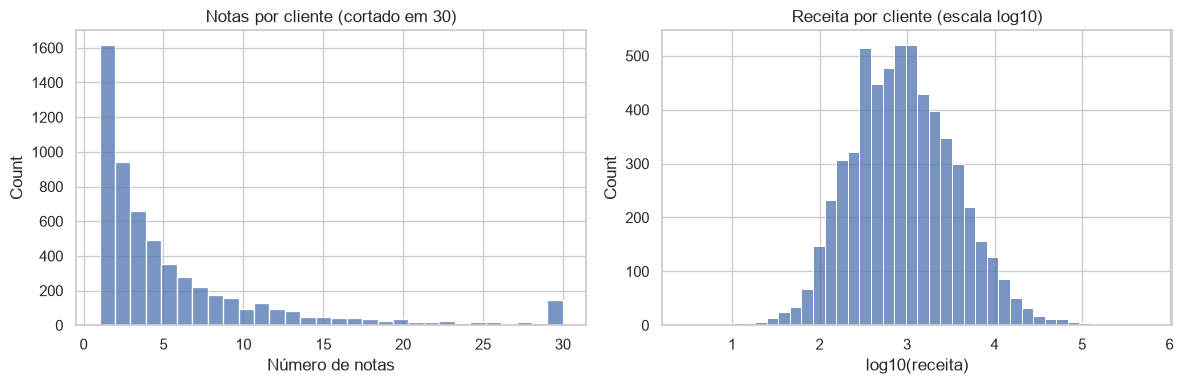

,notas,receita
count,"5,853.00","5,853.00"
mean,6.26,"2,918.52"
std,12.76,"14,335.51"
min,1.00,2.95
25%,1.00,340.85
50%,3.00,856.03
75%,7.00,"2,240.90"
max,375.00,"580,987.04"


In [12]:
clientes = clean.groupby("CustomerID").agg(
    notas=("Invoice", "nunique"),
    receita=("Revenue", "sum"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(clientes["notas"].clip(upper=30), bins=30, ax=axes[0])
axes[0].set_title("Notas por cliente (cortado em 30)")
axes[0].set_xlabel("Número de notas")

sns.histplot(np.log10(clientes["receita"]), bins=40, ax=axes[1])
axes[1].set_title("Receita por cliente (escala log10)")
axes[1].set_xlabel("log10(receita)")

plt.tight_layout()
fig.savefig(FIGURES / "01_distribuicao_clientes.png", dpi=150)
plt.show()

clientes.describe()

A distribuição de receita e de notas por cliente é **muito assimétrica** (poucos clientes compram muito). Isso importa para a clusterização: K-Means e GMM sofrem com variáveis assimétricas, então na etapa de features vou aplicar **transformação logarítmica** antes de padronizar.

### Concentração de receita (Pareto)

Os 20% de clientes que mais compram respondem por 77.2% da receita


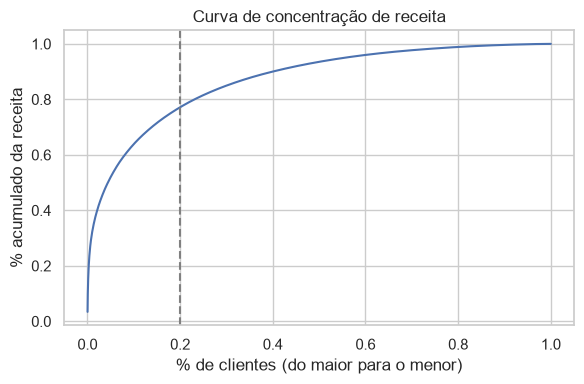

In [13]:
ordenado = clientes["receita"].sort_values(ascending=False)
acumulado = ordenado.cumsum() / ordenado.sum()
pct_clientes = np.arange(1, len(ordenado) + 1) / len(ordenado)

top20 = acumulado[pct_clientes <= 0.20].iloc[-1]
print(f"Os 20% de clientes que mais compram respondem por {top20:.1%} da receita")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pct_clientes, acumulado.values)
ax.axvline(0.20, color="gray", linestyle="--")
ax.set_xlabel("% de clientes (do maior para o menor)")
ax.set_ylabel("% acumulado da receita")
ax.set_title("Curva de concentração de receita")
plt.tight_layout()
fig.savefig(FIGURES / "01_pareto_receita.png", dpi=150)
plt.show()

## 6. Salvando a base limpa

In [14]:
cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID", "Country", "Revenue"]
PROCESSED.parent.mkdir(parents=True, exist_ok=True)
clean[cols].to_csv(PROCESSED, index=False)
print(f"Salvo em {PROCESSED} ({len(clean):,} linhas)")

Salvo em ..\data\processed\transactions_clean.csv (776,840 linhas)


## Conclusões e próximos passos

- Registre aqui os números que apareceram: % de linhas sem `CustomerID`, % de cancelamentos, país dominante, concentração de receita.
- A base limpa está em `data/processed/transactions_clean.csv`.
- **Próximo notebook (`02_rfm.ipynb`):** calcular Recência, Frequência e Valor Monetário por cliente, com uma data de referência fixa.